<a href="https://colab.research.google.com/github/r00trahaf/Arabic-AI-Text-Detection-MSIS-822Project/blob/main/Notebook/%20MSIS822_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSIS-822: Advanced Data Analytic Techniques
1. **Phase 1: Project Setup & Data Acquisition** (Standard repository structure, Hugging Face data loading, structural inspection, class balance, missing values, duplicates & consistency checks).
2. **Phase 2: Data Preprocessing & Exploratory Data Analysis (EDA)** (Non-destructive Arabic NLP pipeline: normalization, diacritics/tatweel removal, stopwords removal, ISRI stemming; plus statistical, lexical, and visual EDA including TTR, Word Clouds, and Top N-grams).
3. **Phase 3: Feature Engineering & Leak-Free Data Splitting** (Group-stratified `70/15/15` split into Train/Validation/Test **before** feature extraction/scaling, engineering assigned stylometric features `10, 32, 54, 76, 98` alongside TF-IDF representations).


---
## Phase 1: Project Setup & Data Acquisition
* **Task 1.1:** Establish standard repository directory structure (`data/raw`, `data/processed`, `notebooks`, `src`, `models`, `reports/figures`, `docs`).
* **Task 1.2:** Load `KFUPM-JRCAI/arabic-generated-abstracts` directly via Hugging Face `datasets`.
* **Task 1.3:** Inspect structure, target variable distribution (`Human` vs. `AI`), missing values, duplicates, and data consistency.


In [ ]:
# Install required libraries (for Google Colab / fresh environments)
!pip install -q datasets nltk arabic-reshaper python-bidi wordcloud transformers torch scikit-learn pandas numpy matplotlib seaborn joblib


In [ ]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")

# Task 1.1: Create standardized project folder structure
project_dirs = [
    "data/raw",
    "data/processed",
    "data/external",
    "notebooks",
    "src",
    "models",
    "reports/figures",
    "reports/presentations",
    "docs"
]
for d in project_dirs:
    os.makedirs(d, exist_ok=True)

print("Project directory structure verified:")
for d in project_dirs:
    print(f"  - {d}/")


Project directory structure verified:
  - data/raw/
  - data/processed/
  - data/external/
  - notebooks/
  - src/
  - models/
  - reports/figures/
  - reports/presentations/
  - docs/


In [ ]:
# Task 1.2: Download dataset from Hugging Face
dataset = load_dataset("KFUPM-JRCAI/arabic-generated-abstracts")
print("Available dataset splits:", list(dataset.keys()))

# Select the 'from_title_and_content' split (2,574 base records across 1 human + 4 AI models)
raw_split_df = dataset["from_title_and_content"].to_pandas()
raw_split_df.to_csv("data/raw/from_title_and_content_raw.csv", index=False)

print(f"Raw split shape: {raw_split_df.shape}")
print("Columns:", raw_split_df.columns.tolist())
raw_split_df.head(2)


Available dataset splits: ['by_polishing', 'from_title', 'from_title_and_content']
Raw split shape: (2574, 5)
Columns: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract']


,original_abstract,allam_generated_abstract,jais_generated_abstract,llama_generated_abstract,openai_generated_abstract
0,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خاصة منها كتب التراجم والفهرسات والبرامج وغيرها بدراسة حياة العلماء والرواة والقضاة والساسة...,يتناول هذا البحث موضوع نظام التعليم عند المرأة الأندلسية خلال العصور الإسلامية. يركز البحث على دور المرأة في الإنتاج الفكري والثقافي الأ...,تتناول هذه الدراسة نظام التعليم عند المرأة الأندلسية، حيث كانت المرأة تشارك في الإنتاج الفكري والثقافي في الأندلس. وقد اشتهرت العديد من ...,تناولت هذه الدراسة نظام التعليم عند المرأة الأندلسية، حيث كانت المرأة تلعب دورًا هامًا في الفكر الأندلسي والنتاج الفكري. لم يكن العلم وا...,يركز البحث على نظام التعليم للمرأة في الأندلس، مستعرضاً دور النساء في الحياة الفكرية والثقافية في تلك الحقبة. وعلى الرغم من هيمنة الرجال...
1,يعد العامل الثقافي احد ابرز الاسباب التي يعزى لها سقوط الدولة الموحدية ، حتى أنه لايقل من حيث التأثير عن بقية العوامل خاصة السياسية و ال...,يتناول هذا البحث دراسة خلفيات انهيار دولة الموحدين من منظور ثقافي. يشير البحث إلى أن العامل الثقافي كان أحد أبرز الأسباب التي أدت إلى سق...,يعد العامل الثقافي أحد أبرز الأسباب التي أدت إلى سقوط الدولة الموحدية، حيث كان له تأثير كبير على الدولة، خاصة فيما يتعلق بالنواحي السياس...,انهيار دولة الموحدين – دراسة في الخلفيات الثقافية – يعد العامل الثقافي أحد أبرز الأسباب التي يعزى إليها سقوط الدولة الموحدية، حتى أن الب...,تناول البحث انهيار دولة الموحدين من منظور خلفياتها الثقافية، مُبرزا الدور الكبير للعوامل الثقافية في هذا السقوط مقارنة بالعوامل السياسية...


In [ ]:
# Transform wide format (original + 4 AI models) into binary classification format (Human vs AI)
records = []

# Human abstracts
for idx, row in raw_split_df.iterrows():
    records.append({
        "source_id": idx,
        "model_source": "human",
        "raw_text": row["original_abstract"],
        "label": "Human",
        "target": 0
    })

# AI-generated abstracts
ai_columns = [
    ("allam_generated_abstract", "allam"),
    ("jais_generated_abstract", "jais"),
    ("llama_generated_abstract", "llama"),
    ("openai_generated_abstract", "openai")
]

for col_name, model_name in ai_columns:
    for idx, row in raw_split_df.iterrows():
        records.append({
            "source_id": idx,
            "model_source": model_name,
            "raw_text": row[col_name],
            "label": "AI",
            "target": 1
        })

df = pd.DataFrame(records)

# Task 1.3: Initial Data Exploration & Quality Assessment
print("=== Dataset Shape & Data Types ===")
print(f"Total samples: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.dtypes)

print("\n=== Missing Values Check ===")
print(df.isnull().sum())

print("\n=== Empty / Whitespace-Only Strings Check ===")
empty_count = df["raw_text"].astype(str).str.strip().eq("").sum()
print(f"Empty strings: {empty_count}")

print("\n=== Duplicate Texts Check ===")
exact_dups = df.duplicated(subset=["raw_text"]).sum()
print(f"Exact duplicate texts: {exact_dups}")
if exact_dups > 0:
    print("Duplicate breakdown by label:")
    print(df[df.duplicated(subset=["raw_text"], keep=False)]["label"].value_counts())

print("\n=== Target Variable Distribution (Class Balance) ===")
class_counts = df["label"].value_counts()
class_props = df["label"].value_counts(normalize=True) * 100
balance_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_props.round(2)})
display(balance_df)

print("\n=== Breakdown by Generation Model ===")
display(df["model_source"].value_counts())


=== Dataset Shape & Data Types ===
Total samples: 12870 rows, 5 columns
source_id        int64
model_source    object
raw_text        object
label           object
target           int64
dtype: object

=== Missing Values Check ===
source_id       0
model_source    0
raw_text        0
label           0
target          0
dtype: int64

=== Empty / Whitespace-Only Strings Check ===
Empty strings: 0

=== Duplicate Texts Check ===
Exact duplicate texts: 3
Duplicate breakdown by label:
label
AI    4
Name: count, dtype: int64

=== Target Variable Distribution (Class Balance) ===


,Count,Percentage (%)
label,,
AI,10296,80.0
Human,2574,20.0



=== Breakdown by Generation Model ===


,count
model_source,
human,2574
allam,2574
jais,2574
llama,2574
openai,2574


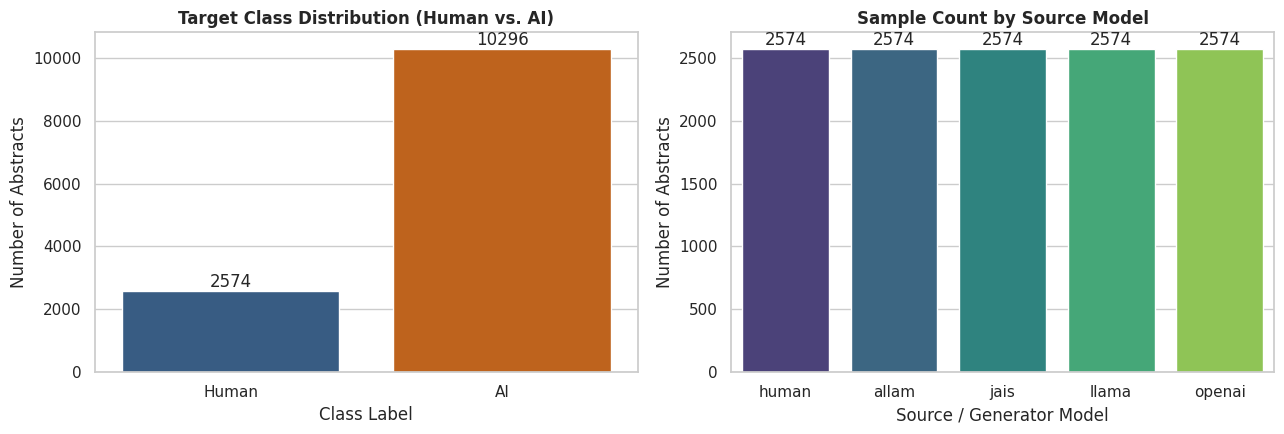

In [ ]:
# Visualize Class Distribution (Phase 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="label", ax=axes[0], palette=["#2b5c8f", "#d95f02"])
axes[0].set_title("Target Class Distribution (Human vs. AI)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Class Label")
axes[0].set_ylabel("Number of Abstracts")
for container in axes[0].containers:
    axes[0].bar_label(container)

sns.countplot(data=df, x="model_source", ax=axes[1], palette="viridis")
axes[1].set_title("Sample Count by Source Model", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Source / Generator Model")
axes[1].set_ylabel("Number of Abstracts")
for container in axes[1].containers:
    axes[1].bar_label(container)

plt.tight_layout()
plt.savefig("reports/figures/phase1_class_distribution.png", dpi=300)
plt.show()


---
## Phase 2: Data Preprocessing & Exploratory Data Analysis (EDA)
* **Design Principle (Preserving Stylometric Integrity):** Raw text is preserved untouched in `raw_text` so that Phase 3 stylometric features (quotation marks, foreign letters, word length, passive constructions, and BERT `[CLS]` token probability) are never distorted. All NLP cleaning steps are written to `processed_text`.
* **Task 2.1 (Arabic Preprocessing Pipeline):**
  1. Removal of Arabic diacritics (Tashkeel) and Tatweel (kashida).
  2. Orthographic normalization (`أ/إ/آ -> ا`, `ى -> ي`, `ؤ/ئ -> ء`, `ة -> ه`).
  3. Removal of non-Arabic characters, digits, and punctuation.
  4. Stop-word removal using NLTK Arabic stopwords.
  5. Root stemming using `ISRIStemmer`.
* **Task 2.2 (Thorough EDA):**
  * Statistical & lexical comparisons (word count, character count, average word length, sentence length, Type-Token Ratio `TTR`, diacritics, tatweel, punctuation).
  * Visualizations: distributions, Word Clouds per class, and Top Bigrams.


In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

nltk.download("stopwords", quiet=True)

arabic_stopwords = set(stopwords.words("arabic"))
stemmer = ISRIStemmer()

def clean_arabic_for_display(text: str) -> str:
    """Clean Arabic text without stemming (ideal for N-grams & Word Clouds)."""
    text = str(text)
    text = re.sub(r"[\u064B-\u065F\u0670\u0640]", "", text)
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"[ؤئ]", "ء", text)
    text = re.sub(r"[^\u0621-\u064A\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [w for w in text.split() if w not in arabic_stopwords and len(w) > 1]
    return " ".join(tokens)

def preprocess_arabic_pipeline(text: str) -> str:
    """Full Arabic preprocessing pipeline: normalization, diacritics/stopword removal, and ISRI stemming."""
    text = str(text)
    # 1. Remove diacritics (tashkeel) and elongation (tatweel)
    text = re.sub(r"[\u064B-\u065F\u0670\u0640]", "", text)
    # 2. Character normalization
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"[ؤئ]", "ء", text)
    text = re.sub(r"ة", "ه", text)
    # 3. Remove non-Arabic characters, numbers, and punctuation
    text = re.sub(r"[^\u0621-\u064A\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    # 4. Tokenization, stop-word removal & ISRI stemming
    tokens = text.split()
    stemmed_tokens = [
        stemmer.stem(tok) for tok in tokens
        if tok not in arabic_stopwords and len(tok) > 1
    ]
    return " ".join(stemmed_tokens)

# Apply preprocessing into separate columns while keeping 'raw_text' intact
df["clean_text_nostem"] = df["raw_text"].apply(clean_arabic_for_display)
df["processed_text"] = df["raw_text"].apply(preprocess_arabic_pipeline)

# Inspect before vs. after preprocessing
pd.set_option("display.max_colwidth", 140)
display(df[["label", "raw_text", "clean_text_nostem", "processed_text"]].head(3))

# Save preprocessed dataset
df.to_csv("data/processed/preprocessed_abstracts.csv", index=False)
print("Saved preprocessed dataset to data/processed/preprocessed_abstracts.csv")


,label,raw_text,clean_text_nostem,processed_text
0,Human,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خاصة منها كتب التراجم والفهرسات والبرامج وغيرها بدراسة حياة العلماء والرواة والقضاة والساسة...,ارتبطت المصادر التاريخية الاندلس كتب التراجم والفهرسات والبرامج وغيرها بدراسة حياة العلماء والرواة والقضاة والساسة وقد تطورت المادة حتي ...,ربط صدر ارخ دلس خصه كتب رجم هرس رمج وغر درس حيه علماء روه قضه سسه وقد تطر اده حتي ءلف دلس لسل واصل حلق كتب رجم صله لبن شكوال وصل صله لبن...
1,Human,يعد العامل الثقافي احد ابرز الاسباب التي يعزى لها سقوط الدولة الموحدية ، حتى أنه لايقل من حيث التأثير عن بقية العوامل خاصة السياسية و ال...,يعد العامل الثقافي احد ابرز الاسباب يعزي سقوط الدولة الموحدية حتي انه لايقل التاثير بقية العوامل السياسية العسكرية فالتركيب الفكري لعقيد...,يعد عمل ثقف احد برز سبب يعز سقط دول وحد حتي انه يقل اثر بقه عمل خصه سيس عسكر فالتركيب فكر عقد ابن ومر عبر ركز سسي قيم دول وحد حوي علي نق...
2,Human,شكلت تلك الجهود والمساعي الرائدة التي قام بها قادة الثورة خلال مرحلتها الأولى (1954-1956) للبحث عن مصادر لتمويل الثورة بالأسلحة والذخيرة...,شكلت الجهود والمساعي الراءدة قادة الثورة خلال مرحلتها الاولي للبحث مصادر لتمويل الثورة بالاسلحة والذخيرة سواء الداخل انطلاقا المناطق الح...,شكل جهد سعي رءد قده ثور خلل رحل اول بحث صدر مول ثور سلح ذخر سوء دخل طلق نطق حدد شرق غرب طقه اول ثني خمس فضل دور برز لعب صطف بن لعد عبس غ...


Saved preprocessed dataset to data/processed/preprocessed_abstracts.csv


In [ ]:
# Task 2.2: Statistical & Lexical EDA
def extract_eda_metrics(row):
    raw = str(row["raw_text"])
    proc_tokens = str(row["processed_text"]).split()
    raw_words = raw.split()

    sentences = [s.strip() for s in re.split(r"[.؟!؛\n]+", raw) if s.strip()]
    num_sentences = max(len(sentences), 1)

    char_count = len(raw)
    word_count = len(raw_words)
    avg_word_len = np.mean([len(w) for w in raw_words]) if raw_words else 0.0
    avg_sent_len = word_count / num_sentences
    ttr = len(set(proc_tokens)) / len(proc_tokens) if proc_tokens else 0.0

    diacritics_count = len(re.findall(r"[\u064B-\u065F\u0670]", raw))
    tatweel_count = raw.count("\u0640")
    latin_count = len(re.findall(r"[A-Za-z]", raw))
    punct_count = len(re.findall(r"[.,;:!?،؛؟\"\'()\[\]-]", raw))

    return pd.Series([
        char_count, word_count, avg_word_len, avg_sent_len, ttr,
        diacritics_count, tatweel_count, latin_count, punct_count
    ], index=[
        "char_count", "word_count", "avg_word_len", "avg_sentence_len", "ttr",
        "diacritics_count", "tatweel_count", "latin_count", "punct_count"
    ])

eda_cols = [
    "char_count", "word_count", "avg_word_len", "avg_sentence_len", "ttr",
    "diacritics_count", "tatweel_count", "latin_count", "punct_count"
]
df[eda_cols] = df.apply(extract_eda_metrics, axis=1)

print("=== Comparative EDA Summary (Mean & Median by Class) ===")
summary_stats = df.groupby("label")[eda_cols].agg(["mean", "median"]).round(3)
display(summary_stats)


=== Comparative EDA Summary (Mean & Median by Class) ===


char_count        word_count        avg_word_len         \
            mean median       mean median         mean median   
label                                                           
AI       671.206  672.0    104.523  105.0        5.440  5.440   
Human    740.035  690.5    119.164  110.0        5.234  5.222   

      avg_sentence_len            ttr        diacritics_count         \
                  mean  median   mean median             mean median   
label                                                                  
AI              19.488  19.167  0.654  0.662            2.938    2.0   
Human           55.032  45.333  0.721  0.727            4.128    0.0   

      tatweel_count        latin_count        punct_count         
               mean median        mean median        mean median  
label                                                             
AI            0.048    0.0       0.597    0.0      11.660   11.0  
Human         0.991    0.0       0.789    0.0      12.749   11.0

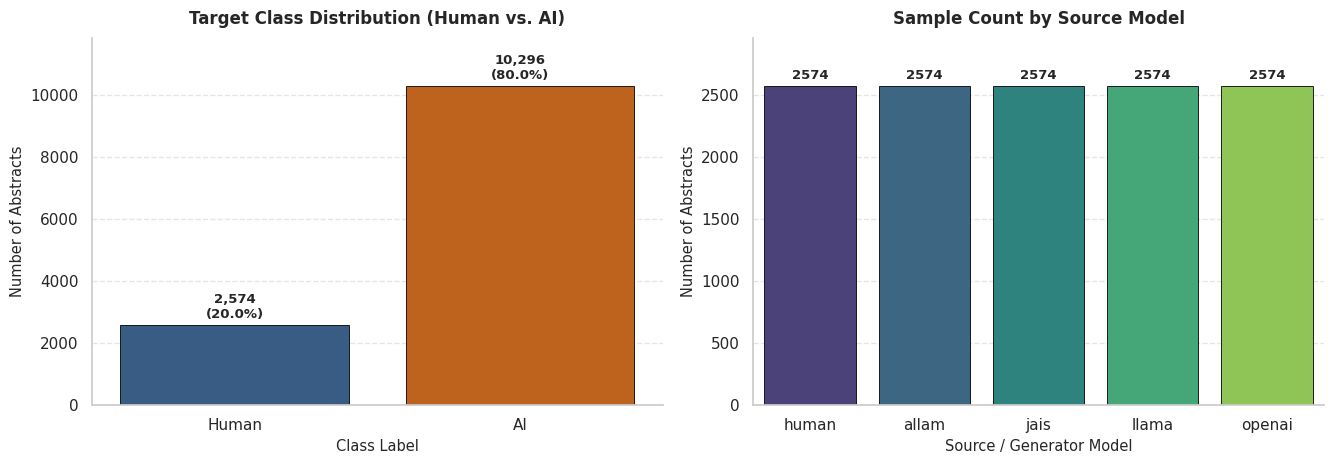

In [ ]:
# Visualize Class Distribution (Phase 1) - Adjusted plot only, keeping exact labels
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Left plot: Target Class Distribution
class_order = ["Human", "AI"]
ax0 = sns.countplot(
    data=df,
    x="label",
    order=class_order,
    ax=axes[0],
    palette=["#2b5c8f", "#d95f02"],
    edgecolor="black",
    linewidth=0.6
)
axes[0].set_title("Target Class Distribution (Human vs. AI)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Class Label", fontsize=10.5)
axes[0].set_ylabel("Number of Abstracts", fontsize=10.5)
axes[0].set_ylim(0, df["label"].value_counts().max() * 1.15)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].set_axisbelow(True)

total_samples = len(df)
for container in ax0.containers:
    labels = [
        f"{int(bar.get_height()):,}\n({bar.get_height() / total_samples * 100:.1f}%)"
        for bar in container
    ]
    ax0.bar_label(container, labels=labels, padding=3, fontsize=9.5, fontweight="bold")

# Right plot: Sample Count by Source Model
model_order = ["human", "allam", "jais", "llama", "openai"]
ax1 = sns.countplot(
    data=df,
    x="model_source",
    order=model_order,
    ax=axes[1],
    palette="viridis",
    edgecolor="black",
    linewidth=0.6
)
axes[1].set_title("Sample Count by Source Model", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Source / Generator Model", fontsize=10.5)
axes[1].set_ylabel("Number of Abstracts", fontsize=10.5)
axes[1].set_ylim(0, df["model_source"].value_counts().max() * 1.15)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].set_axisbelow(True)

for container in ax1.containers:
    ax1.bar_label(container, fmt="%d", padding=3, fontsize=9.5, fontweight="bold")

sns.despine(fig=fig)
plt.tight_layout()
plt.savefig("reports/figures/phase1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

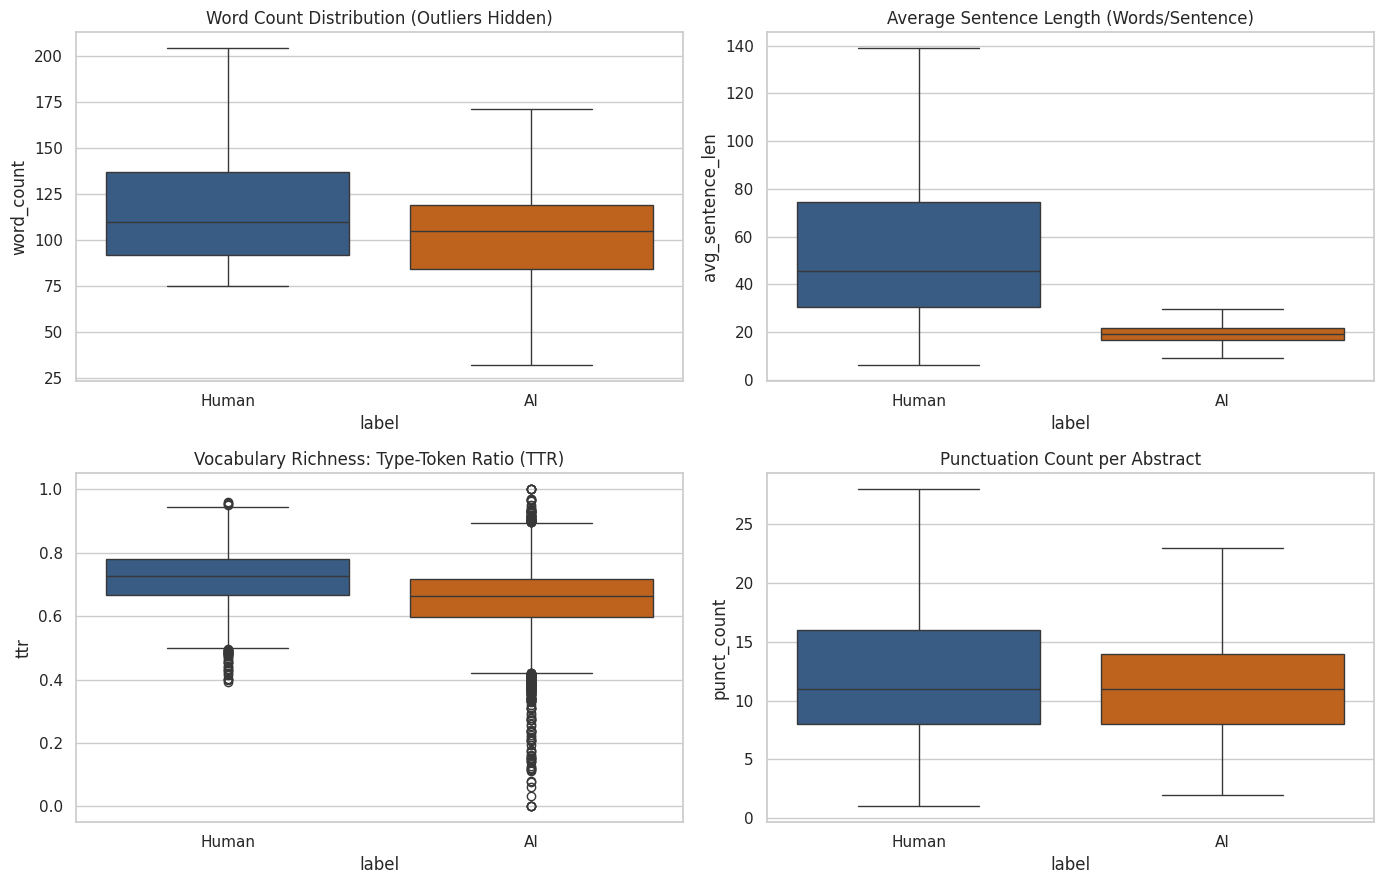

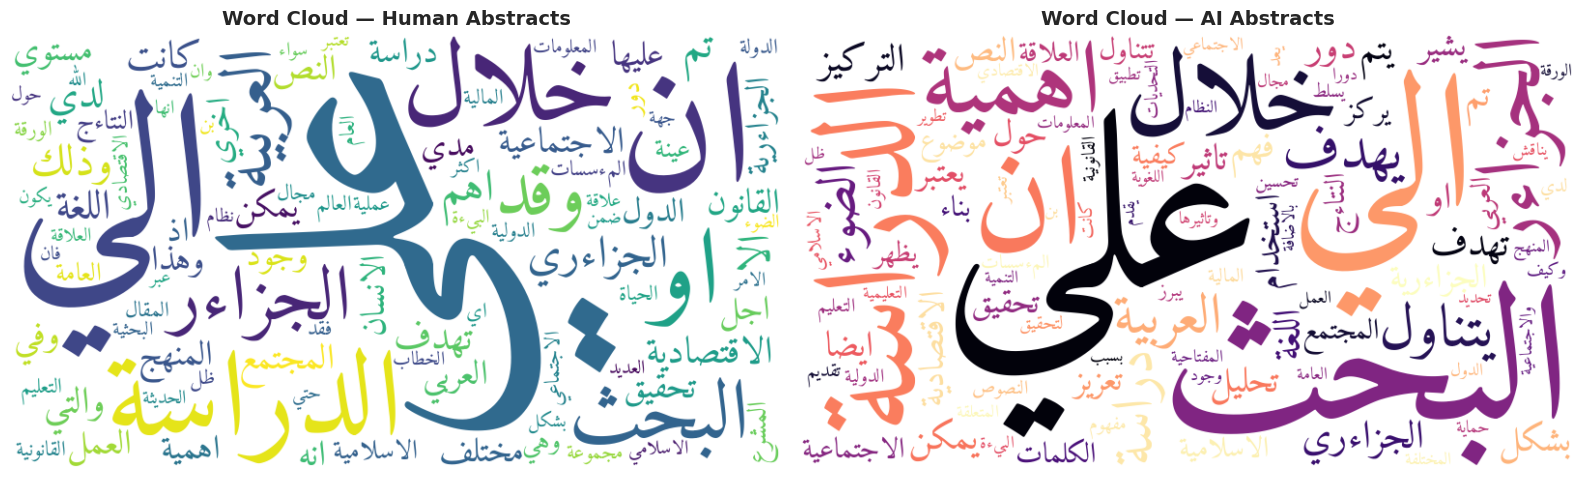


Top 10 Bigrams — Human:
  الدراسة الي: 595
  الي ان: 252
  تهدف الدراسة: 238
  الورقة البحثية: 182
  الضوء علي: 164
  اللغة العربية: 159
  المنهج الوصفي: 153
  التعرف علي: 146
  المشرع الجزاءري: 145
  الكلمات المفتاحية: 141

Top 10 Bigrams — AI:
  البحث الي: 4321
  الدراسة الي: 3274
  الي ان: 2758
  الضوء علي: 2746
  يتناول البحث: 2714
  يهدف البحث: 2385
  التركيز علي: 2352
  علي اهمية: 2023
  البحث علي: 1982
  تهدف الدراسة: 1731


In [ ]:
from wordcloud import WordCloud
import arabic_reshaper
from bidi.algorithm import get_display
from sklearn.feature_extraction.text import CountVectorizer
import urllib.request
from collections import Counter
from bidi.algorithm import get_display
from wordcloud import WordCloud

# 1. Distribution plots for key lexical metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=df, x="label", y="word_count", ax=axes[0, 0], showfliers=False, palette=["#2b5c8f", "#d95f02"])
axes[0, 0].set_title("Word Count Distribution (Outliers Hidden)")

sns.boxplot(data=df, x="label", y="avg_sentence_len", ax=axes[0, 1], showfliers=False, palette=["#2b5c8f", "#d95f02"])
axes[0, 1].set_title("Average Sentence Length (Words/Sentence)")

sns.boxplot(data=df, x="label", y="ttr", ax=axes[1, 0], palette=["#2b5c8f", "#d95f02"])
axes[1, 0].set_title("Vocabulary Richness: Type-Token Ratio (TTR)")

sns.boxplot(data=df, x="label", y="punct_count", ax=axes[1, 1], showfliers=False, palette=["#2b5c8f", "#d95f02"])
axes[1, 1].set_title("Punctuation Count per Abstract")

plt.tight_layout()
plt.savefig("reports/figures/phase2_eda_distributions.png", dpi=300)
plt.show()

# 2. Word Clouds for Human vs. AI

# 1. التأكد من وجود خط عربي يدعم الحروف العربية بوضوح
font_path = "Amiri-Regular.ttf"
if not os.path.exists(font_path):
    font_url = "https://github.com/google/fonts/raw/main/ofl/amiri/Amiri-Regular.ttf"
    try:
        urllib.request.urlretrieve(font_url, font_path)
    except Exception as e:
        print("تعذر تحميل خط Amiri تلقائياً، جاري البحث عن خط بديل:", e)
        fallbacks = [
            "/usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf",
            "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
        ]
        font_path = next((f for f in fallbacks if os.path.exists(f)), None)

# وصل الحروف فقط دون get_display لتجنب انعكاس الكلمة داخل WordCloud
def prepare_arabic_for_wordcloud(word: str) -> str:
    return arabic_reshaper.reshape(word)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, lbl in enumerate(["Human", "AI"]):
    words = " ".join(df[df["label"] == lbl]["clean_text_nostem"].dropna().tolist()).split()
    top_words = dict(Counter(words).most_common(120))
    reshaped_freq = {
        prepare_arabic_for_wordcloud(w): freq
        for w, freq in top_words.items()
        if len(w.strip()) > 1
    }

    wc = WordCloud(
        font_path=font_path,
        background_color="white",
        width=800,
        height=450,
        max_words=100,
        colormap="viridis" if lbl == "Human" else "magma"
    ).generate_from_frequencies(reshaped_freq)

    axes[idx].imshow(wc, interpolation="bilinear")
    axes[idx].set_title(f"Word Cloud — {lbl} Abstracts", fontsize=14, fontweight="bold")
    axes[idx].axis("off")

plt.tight_layout()
plt.savefig("reports/figures/phase2_wordclouds.png", dpi=300)
plt.show()

# 3. Top Bigrams Comparison
def get_top_ngrams(corpus, ngram_range=(2, 2), top_k=10):
    vec = CountVectorizer(ngram_range=ngram_range).fit(corpus)
    bag = vec.transform(corpus)
    freqs = np.asarray(bag.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    top_idx = np.argsort(freqs)[::-1][:top_k]
    return list(zip(vocab[top_idx], freqs[top_idx]))

for lbl in ["Human", "AI"]:
    top_bi = get_top_ngrams(df[df["label"] == lbl]["clean_text_nostem"], ngram_range=(2, 2), top_k=10)
    print(f"\nTop 10 Bigrams — {lbl}:")
    for phrase, cnt in top_bi:
        print(f"  {phrase}: {cnt}")


---
## Phase 3: Feature Engineering & Leak-Free Data Splitting
### 1. Leak-Free Stratified Data Splitting (Task 3.2)
* **Crucial Anti-Leakage Step:** Before fitting TF-IDF vectorizers or scalers, the dataset is split into **70% Train / 15% Validation / 15% Test**.
* Moreover, because each `source_id` links 1 human abstract with 4 corresponding AI abstracts, grouping by `source_id` ensures that **no abstract and its AI counterparts ever leak across Train, Validation, and Test sets**.

### 2. Assigned Individual Stylometric Features (Task 3.1)
Using student index $i = 10$ and roster size $n = 22$ in $f_{k+i} = (k \times n) + i$ for $k \in \{0, 1, 2, 3, 4\}$:
1. **Feature #10 (`f10_avg_word_length`):** Average word length across tokens in `raw_text`.
2. **Feature #32 (`f32_double_quotes_count`):** Total number of double quotation marks (`"`, `“`, `”`, `«`, `»`).
3. **Feature #54 (`f54_foreign_letters_count`):** Total count of non-Arabic alphabetic (foreign/Latin) characters (`[A-Za-z]`).
4. **Feature #76 (`f76_passive_voice_sentences`):** Number of Arabic passive voice sentences (detected via morphological passive patterns and periphrastic passive constructions such as `تم + مصدر`, `جرى + مصدر`, `يُعدّ`, `يُعتبر`, `لوحظ`, `أُجريت`, `تُستخدم`).
5. **Feature #98 (`f98_bert_cls_prob`):** Contextual `[CLS]` token probability extracted from a pre-trained Arabic BERT model (`aubmindlab/bert-base-arabertv02`) in frozen mode (zero target leakage).

### 3. Complementary Text Representations
* **Traditional Features:** TF-IDF (1–2 n-grams) fitted **strictly on `X_train`** and applied to `X_val` and `X_test`.
* **Combined Feature Matrices:** Ready-to-model datasets exported to `data/processed/` for Phase 4.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Task 3.2: Leak-free 70% / 15% / 15% split grouped by 'source_id'
gss_temp = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss_temp.split(df, df["target"], groups=df["source_id"]))

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
temp_df = df.iloc[temp_idx].copy().reset_index(drop=True)

# Split the remaining 30% equally into 15% Validation and 15% Test
gss_val_test = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val_test.split(temp_df, temp_df["target"], groups=temp_df["source_id"]))

val_df = temp_df.iloc[val_idx].copy().reset_index(drop=True)
test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)

# Verify zero overlap in source_id across splits
assert set(train_df["source_id"]).isdisjoint(set(val_df["source_id"])), "Leakage between Train and Val!"
assert set(train_df["source_id"]).isdisjoint(set(test_df["source_id"])), "Leakage between Train and Test!"
assert set(val_df["source_id"]).isdisjoint(set(test_df["source_id"])), "Leakage between Val and Test!"

for split_name, split_data in [("Train (70%)", train_df), ("Validation (15%)", val_df), ("Test (15%)", test_df)]:
    ai_ratio = split_data["target"].mean() * 100
    print(f"{split_name:18s} | Samples: {len(split_data):5d} | AI Ratio: {ai_ratio:.2f}%")


Train (70%)        | Samples:  9005 | AI Ratio: 80.00%
Validation (15%)   | Samples:  1930 | AI Ratio: 80.00%
Test (15%)         | Samples:  1935 | AI Ratio: 80.00%


In [ ]:
# Task 3.1: Extract Assigned Stylometric Features (#10, #32, #54, #76)
PASSIVE_REGEX = re.compile(
    r"(?:"
    r"\b(?:تم|يتم|تتم|جرى|يجري|تجري)\s+(?:[\u0621-\u064A]{3,})|"
    r"\b(?:يُ|تُ|نُ|أُ)[\u0621-\u064A]+|"
    r"\b[يتنأ]ُ[\u0621-\u064A]+|"
    r"\b(?:يعتبر|تعتبر|يعد|تعد|يلاحظ|تلاحظ|لوحظ|أجريت|اجريت|نوقشت|استخدمت|صممت|طورت|طبقت)\b"
    r")"
)

def extract_assigned_stylometric_features(text: str) -> pd.Series:
    raw = str(text)

    # Feature #10: Average word length
    words = [w for w in raw.split() if len(w) > 0]
    f10_avg_word_len = float(np.mean([len(w) for w in words])) if words else 0.0

    # Feature #32: Number of double quotes
    f32_double_quotes = len(re.findall(r'[\"“”«»]', raw))

    # Feature #54: Number of foreign letters (Latin / non-Arabic alphabetic characters)
    f54_foreign_letters = len(re.findall(r"[A-Za-z]", raw))

    # Feature #76: Number of Passive voice sentences
    sentences = [s.strip() for s in re.split(r"[.؟!؛\n]+", raw) if s.strip()]
    f76_passive_sentences = sum(1 for s in sentences if PASSIVE_REGEX.search(s))

    return pd.Series(
        [f10_avg_word_len, f32_double_quotes, f54_foreign_letters, f76_passive_sentences],
        index=[
            "f10_avg_word_length",
            "f32_double_quotes_count",
            "f54_foreign_letters_count",
            "f76_passive_voice_sentences"
        ]
    )

stylo_cols = [
    "f10_avg_word_length",
    "f32_double_quotes_count",
    "f54_foreign_letters_count",
    "f76_passive_voice_sentences"
]

for split_data in [train_df, val_df, test_df]:
    split_data[stylo_cols] = split_data["raw_text"].apply(extract_assigned_stylometric_features)

print("=== Assigned Stylometric Features Summary (Train Set by Class) ===")
display(train_df.groupby("label")[stylo_cols].agg(["mean", "median", "max"]).round(3))


=== Assigned Stylometric Features Summary (Train Set by Class) ===


f10_avg_word_length               f32_double_quotes_count               \
                     mean median    max                    mean median   max   
label                                                                          
AI                  5.441  5.440  6.657                   0.474    0.0  36.0   
Human               5.237  5.226  9.239                   0.543    0.0  16.0   

      f54_foreign_letters_count              f76_passive_voice_sentences  \
                           mean median   max                        mean   
label                                                                      
AI                        0.596    0.0  60.0                       1.280   
Human                     0.791    0.0  74.0                       0.492   

                    
      median   max  
label               
AI       1.0  20.0  
Human    0.0   4.0

In [ ]:
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# Feature #98: BERT [CLS] Token Probability using pre-trained AraBERT (aubmindlab/bert-base-arabertv02)
MODEL_NAME = "aubmindlab/bert-base-arabertv02"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Loading {MODEL_NAME} on device: {device} ...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_mlm = AutoModelForMaskedLM.from_pretrained(MODEL_NAME).to(device)
bert_mlm.eval()

cls_token_id = tokenizer.cls_token_id

@torch.no_grad()
def compute_bert_cls_probability(texts, batch_size=32, max_length=256):
    cls_probs = []
    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start : start + batch_size]
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        ).to(device)

        outputs = bert_mlm(**encoded)
        cls_logits = outputs.logits[:, 0, :]
        probs = torch.softmax(cls_logits, dim=-1)
        batch_cls_probs = probs[:, cls_token_id].cpu().numpy()
        cls_probs.extend(batch_cls_probs.tolist())
    return np.array(cls_probs, dtype=np.float64)

for name, split_data in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"Extracting Feature #98 (BERT [CLS] Token Probability) for {name} set...")
    probs_arr = compute_bert_cls_probability(split_data["raw_text"].tolist())
    split_data["f98_bert_cls_prob"] = probs_arr
    split_data["f98_bert_cls_log10"] = np.log10(np.clip(probs_arr, 1e-30, 1.0))

all_assigned_features = stylo_cols + ["f98_bert_cls_prob"]
print("\n=== All 5 Assigned Stylometric Features (Train Set Summary) ===")
display(train_df.groupby("label")[all_assigned_features].agg(["mean", "std"]).round(6))
print("\n=== Feature #98 Log10 Scale Summary (Train Set by Class) ===")
display(train_df.groupby("label")[["f98_bert_cls_log10"]].agg(["mean", "median", "std"]).round(4))

Loading aubmindlab/bert-base-arabertv02 on device: cuda ...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting Feature #98 (BERT [CLS] Token Probability) for Train set...
Extracting Feature #98 (BERT [CLS] Token Probability) for Validation set...
Extracting Feature #98 (BERT [CLS] Token Probability) for Test set...

=== All 5 Assigned Stylometric Features (Train Set Summary) ===


f10_avg_word_length           f32_double_quotes_count            \
                     mean       std                    mean       std   
label                                                                   
AI               5.440657  0.326445                0.474459  1.418052   
Human            5.237186  0.400780                0.543032  1.601894   

      f54_foreign_letters_count           f76_passive_voice_sentences  \
                           mean       std                        mean   
label                                                                   
AI                     0.596474  2.873132                    1.279567   
Human                  0.790672  4.334621                    0.491949   

                f98_bert_cls_prob       
            std              mean  std  
label                                   
AI     1.532332               0.0  0.0  
Human  0.627222               0.0  0.0


=== Feature #98 Log10 Scale Summary (Train Set by Class) ===


f98_bert_cls_log10                 
                    mean   median     std
label                                    
AI              -11.7746 -11.7680  0.6704
Human           -12.2954 -12.2264  0.8682

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
import joblib
from pathlib import Path
from scipy import sparse

Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)

# 1. Fit StandardScaler strictly on Train set for the 5 assigned stylometric features
scaler = StandardScaler()
X_train_stylo = scaler.fit_transform(train_df[all_assigned_features])
X_val_stylo = scaler.transform(val_df[all_assigned_features])
X_test_stylo = scaler.transform(test_df[all_assigned_features])

# 2. Fit TF-IDF Vectorizer strictly on Train set ('processed_text') to avoid vocabulary leakage
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(train_df["processed_text"])
X_val_tfidf = tfidf.transform(val_df["processed_text"])
X_test_tfidf = tfidf.transform(test_df["processed_text"])

print("Feature Matrices Shapes:")
print(f"  Assigned Stylometric (Train/Val/Test): {X_train_stylo.shape}, {X_val_stylo.shape}, {X_test_stylo.shape}")
print(f"  TF-IDF Features      (Train/Val/Test): {X_train_tfidf.shape}, {X_val_tfidf.shape}, {X_test_tfidf.shape}")

# Save engineered splits and fitted transformers for Phase 4 Modeling
train_df.to_csv("data/processed/train_features.csv", index=False)
val_df.to_csv("data/processed/val_features.csv", index=False)
test_df.to_csv("data/processed/test_features.csv", index=False)

np.save("data/processed/X_train_stylo.npy", X_train_stylo)
np.save("data/processed/X_val_stylo.npy", X_val_stylo)
np.save("data/processed/X_test_stylo.npy", X_test_stylo)

sparse.save_npz("data/processed/X_train_tfidf.npz", X_train_tfidf)
sparse.save_npz("data/processed/X_val_tfidf.npz", X_val_tfidf)
sparse.save_npz("data/processed/X_test_tfidf.npz", X_test_tfidf)

joblib.dump(scaler, "models/stylometric_scaler.joblib")
joblib.dump(tfidf, "models/tfidf_vectorizer.joblib")

print("\nPhase 3 completed successfully! All engineered datasets, matrices, and transformers saved.")


Feature Matrices Shapes:
  Assigned Stylometric (Train/Val/Test): (9005, 5), (1930, 5), (1935, 5)
  TF-IDF Features      (Train/Val/Test): (9005, 5000), (1930, 5000), (1935, 5000)

Phase 3 completed successfully! All engineered datasets, matrices, and transformers saved.


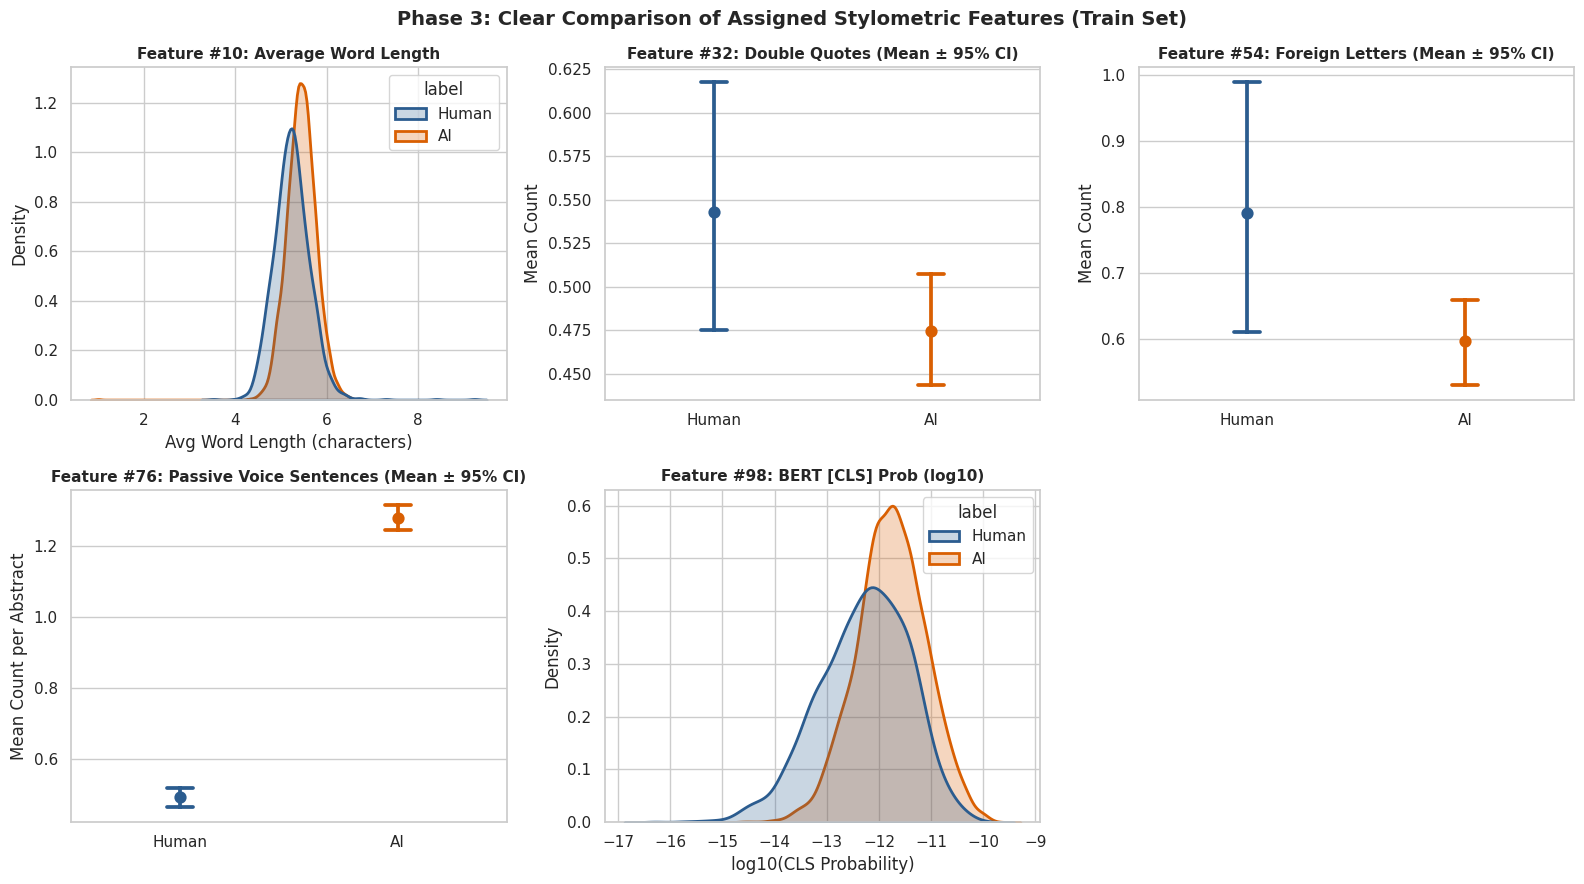

In [ ]:
# Visualize the 5 Assigned Stylometric Features on the Training Set
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = {"Human": "#2b5c8f", "AI": "#d95f02"}

# 1. Feature #10: Average Word Length (KDE / Density)
sns.kdeplot(
    data=train_df, x="f10_avg_word_length", hue="label",
    fill=True, common_norm=False, palette=colors, ax=axes[0], linewidth=2
)
axes[0].set_title("Feature #10: Average Word Length", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Avg Word Length (characters)")

# 2. Feature #32: Double Quotes Count (Mean with 95% CI)
sns.pointplot(
    data=train_df, x="label", y="f32_double_quotes_count",
    palette=colors, errorbar=("ci", 95), linestyles="none", capsize=0.12, ax=axes[1]
)
axes[1].set_title("Feature #32: Double Quotes (Mean ± 95% CI)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean Count")

# 3. Feature #54: Foreign Letters Count (Mean with 95% CI)
sns.pointplot(
    data=train_df, x="label", y="f54_foreign_letters_count",
    palette=colors, errorbar=("ci", 95), linestyles="none", capsize=0.12, ax=axes[2]
)
axes[2].set_title("Feature #54: Foreign Letters (Mean ± 95% CI)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("")
axes[2].set_ylabel("Mean Count")

# 4. Feature #76: Passive Voice Sentences (Mean with 95% CI)
sns.pointplot(
    data=train_df, x="label", y="f76_passive_voice_sentences",
    palette=colors, errorbar=("ci", 95), linestyles="none", capsize=0.12, ax=axes[3]
)
axes[3].set_title("Feature #76: Passive Voice Sentences (Mean ± 95% CI)", fontsize=11, fontweight="bold")
axes[3].set_xlabel("")
axes[3].set_ylabel("Mean Count per Abstract")

# 5. Feature #98: BERT [CLS] Prob (log10 KDE)
sns.kdeplot(
    data=train_df, x="f98_bert_cls_log10", hue="label",
    fill=True, common_norm=False, palette=colors, ax=axes[4], linewidth=2
)
axes[4].set_title("Feature #98: BERT [CLS] Prob (log10)", fontsize=11, fontweight="bold")
axes[4].set_xlabel("log10(CLS Probability)")

axes[5].axis("off")
plt.suptitle("Phase 3: Clear Comparison of Assigned Stylometric Features (Train Set)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("reports/figures/phase3_assigned_features.png", dpi=300)
plt.show()